# Session 16: Introduction to Deep Learning and Image Processing

**Learning goals:**

- Distinguish features, targets and model parameters, and explain training and inference.
- Explain how deeper networks build hierarchical representations.
- Relate algorithms, large datasets and computing hardware to the success of deep learning.
- Identify key contributors to deep learning and image recognition.
- Explain convolution, shared filters, stride, padding, pooling, fully connected layers and softmax.
- Compare LeNet-5, AlexNet, VGGNet and ResNet, including small filters and residual connections.
- Apply image filters and visualise MNIST digit images.
- Train a fully connected neural network and a CNN on the same split, compare held-out predictions and measure CPU/GPU inference time.

**Prerequisites:**

- Supervised learning, classification, train/test splits and model evaluation.
- Basic Python functions, classes, loops and NumPy arrays.
- Python with Pillow, Matplotlib, NumPy, pandas, scikit-learn and PyTorch installed in the notebook environment.
- A GPU is optional; all practical examples can run on CPU.



## Outline

1. From machine learning to deep learning
2. Key scientists and contributors
3. CNN building blocks and image filtering
4. Popular CNN architectures
5. Why networks became deeper rather than only wider
6. Image classification: MNIST, MLP/CNN comparison and CPU/GPU inference

Work through Sections 1–3, including the image-filtering example, before continuing to architectures, model training and evaluation in Sections 4–6.


## 1. From Machine Learning to Deep Learning


### 1.1 Machine learning: learn from history

Machine learning (ML) builds a useful relationship from historical examples. In **supervised learning**, each example pairs **features** (the input measurements or attributes) with a known **target** (the value or class to predict). For digit recognition, the features are pixel values and the target is the digit label.

Instead of manually writing every rule, practitioners select a **method/algorithm** that learns the relationship between features and targets. Training uses the historical feature–target pairs to adjust **model parameters**, such as weights and biases. These parameters represent the learnt relationship between features and targets; they are different from the features and targets in the dataset.

During **inference**, the trained model receives features for a new case and produces a **predicted target**. The known target for that new case is not supplied as an input to the model.

![Historical features and known targets train model parameters that represent their relationship. The trained model maps new features to a predicted target.](assets/ml-learning-from-history.svg){fig-alt="Historical feature–target pairs pass through a learning algorithm to produce parameters representing the relationship between features and targets. The trained model maps new features to a predicted target." style="width: 100%; height: auto;"}


### 1.2 Why add more layers?

A single layer can capture a limited transformation. Multiple layers can build a hierarchy: early layers detect simple patterns, middle layers combine them, and later layers form task-specific concepts. The CNN below illustrates the progression from edges and textures to outlines, shapes and a final class prediction.

![A dog image passes through CNN layers that learn edges, outlines, textures and shapes before a classifier predicts dog](assets/cnn-dog-feature-extraction.png){fig-alt="A dog image passes through CNN layers that learn edges, outlines, textures and shapes before a classifier predicts dog" style="width: 100%; height: auto;"}

- **Early layers:** local edges and colour changes
- **Middle layers:** textures, contours and reusable parts
- **Later layers:** whole-object evidence and a task output


### 1.3 Why deep learning became successful

![Algorithms update network weights from errors, big data supplies many input-output examples, and a GPU processes matrix operations in parallel](assets/why-deep-learning.svg){fig-alt="Three panels show error-driven weight updates, many historical input-output pairs, and parallel GPU matrix processing" style="width: 100%; height: auto;"}

- **Algorithms:** backpropagation, improved activation functions, optimisation methods and model architectures made deeper networks easier to train.
- **Big data:** more historical examples exposed useful patterns and supported models with greater capacity.
- **Higher-performance computing:** GPUs, specialised accelerators and distributed training made large-scale calculations practical.


## 2 - Key Scientists and Contributors

Modern image recognition is the result of many people and many research groups. The names below are useful starting points for students because each one connects to a different part of the story.

| Scientist | Why they matter for deep learning and image recognition |
|---|---|
| [Geoffrey Hinton](https://en.wikipedia.org/wiki/Geoffrey_Hinton) | Helped revive neural networks, popularised representation learning, co-authored the AlexNet paper, and contributed to backpropagation, Boltzmann machines, and knowledge distillation. |
| [Yann LeCun](https://en.wikipedia.org/wiki/Yann_LeCun) | Developed LeNet-style CNNs for handwritten digit recognition and made convolutional networks central to computer vision. |
| [Yoshua Bengio](https://en.wikipedia.org/wiki/Yoshua_Bengio) | Helped develop deep learning theory and representation learning, especially for training deep neural networks. |
| [Fei-Fei Li](https://en.wikipedia.org/wiki/Fei-Fei_Li) | Led work on ImageNet, a large labelled image dataset that helped make large-scale visual recognition measurable and competitive. |
| [Kunihiko Fukushima](https://en.wikipedia.org/wiki/Kunihiko_Fukushima) | Proposed the Neocognitron, an early biologically inspired model with ideas similar to later convolution and pooling. |
| [Jürgen Schmidhuber](https://en.wikipedia.org/wiki/J%C3%BCrgen_Schmidhuber) | Contributed to deep learning and recurrent networks, and his group worked on early GPU-accelerated neural networks. |
| [Kaiming He](https://en.wikipedia.org/wiki/Kaiming_He) | Co-authored ResNet and He initialisation, both important for training very deep networks. |

A useful way to read this history is not as one inventor story, but as a stack of ideas: datasets, compute, architectures, optimisation methods, and open-source tools all improved together.


## 3 - CNN Building Blocks

[Video: CNNs](https://www.youtube.com/watch?v=ip2HYPC_T9Q)


{{< video https://www.youtube.com/embed/ip2HYPC_T9Q?hl=en title="CNNs" aria-label="Video explaining convolutional neural networks" aspect-ratio="16x9" >}}


A CNN for image classification can be understood as four main parts. The early layers extract useful visual features; the final layers turn those features into a class prediction.

| Component | Role |
|---|---|
| **Convolutional layer** | Uses learnable filters to extract local features such as edges, corners, textures, and shapes. |
| **Pooling layer** | Shrinks feature maps while keeping the strongest or average signal in each local region. |
| **Fully connected layer** | Combines extracted features to produce class scores. |
| **Softmax** | Converts class scores into probabilities that sum to 1. |


### 3.1 CNN Network Structure

The diagram below shows a typical CNN flow: image input, repeated convolution and pooling, then fully connected layers and a final prediction.

![Typical CNN architecture](assets/typical-cnn-architecture.png)

Interactive 3D demo: [Adam Harley - CNN 3D Visualisation](https://adamharley.com/nn_vis/cnn/3d.html). This visualisation shows how feature maps change as an image moves through a CNN.

Reference: inspired by [Pinecone - Visual Guide to Applied Convolution Neural Networks](https://www.pinecone.io/learn/series/image-search/cnn/). Images in this notebook are stored locally so they display offline.


### 3.2 Convolutional Layer: Filters Extract Features

A convolutional layer uses small filters to scan an image. Different filters respond to different visual patterns. For example, one filter may respond strongly to vertical edges, another to horizontal edges, and another to sharp outlines.

The animation below shows how a filter produces a feature map: the filter moves over the image, calculates one local response at a time, and builds a new representation for the next layer.

![Convolution filter producing a feature map](assets/convolution-filter-feature-map.gif)


### 3.3 Convolutional Computing

At each image position, the filter and the image patch are multiplied element by element. The products are then added together. That one number becomes one value in the output feature map.

![Convolution element-wise multiplication](assets/convolution-elementwise.png)

After this visual explanation, the next code cell applies several filters to the dog image to show how different filters highlight different features.


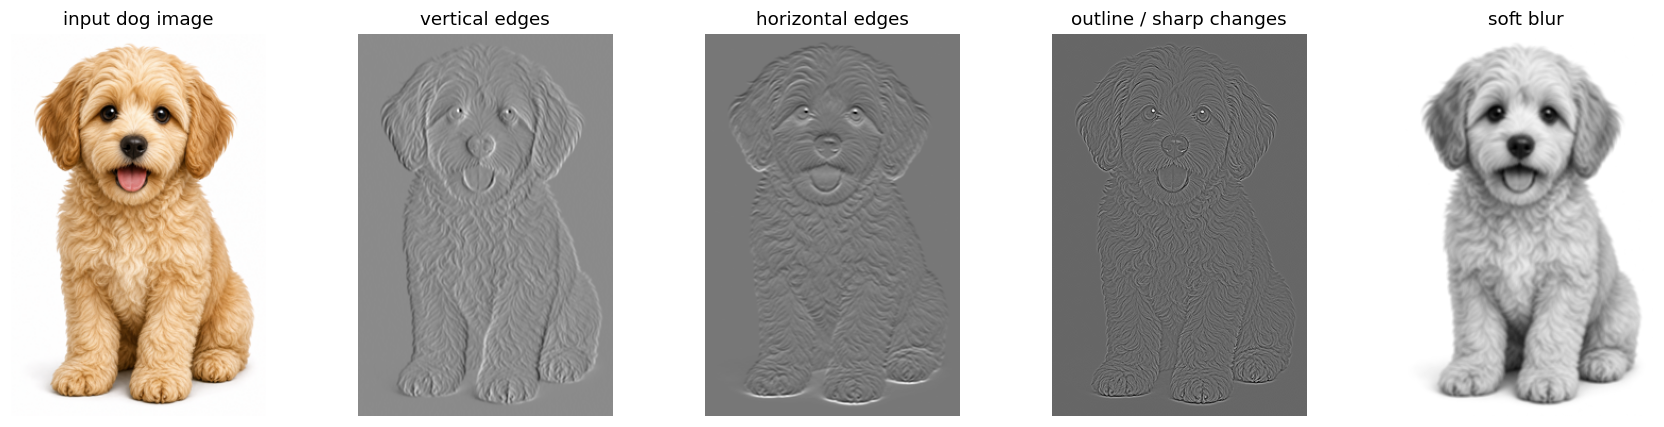

In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

DOG_IMAGE = "assets/dog_input.png"

# Load the image as RGB. Even though the filters below use greyscale, keeping the
# RGB version lets us display the original image beside the feature maps.
dog_rgb = Image.open(DOG_IMAGE).convert("RGB")

# Shrink the image so the nested loops below run quickly in a classroom notebook.
dog_rgb.thumbnail((360, 360))

# Convert image pixels from integers in [0, 255] to floats in [0, 1].
dog_rgb_array = np.asarray(dog_rgb, dtype=np.float32) / 255.0

# Convert RGB to greyscale using standard luminance weights.
# This gives one intensity value per pixel, which is easier for 2D filters.
dog_gray = (
    0.299 * dog_rgb_array[:, :, 0]
    + 0.587 * dog_rgb_array[:, :, 1]
    + 0.114 * dog_rgb_array[:, :, 2]
)

# Each small matrix below is a filter/kernel. Positive and negative values make
# the filter respond strongly to different patterns, such as edges or outlines.
filters = {
    "vertical edges": np.array(
        [
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1],
        ],
        dtype=np.float32,
    ),
    "horizontal edges": np.array(
        [
            [-1, -2, -1],
            [0, 0, 0],
            [1, 2, 1],
        ],
        dtype=np.float32,
    ),
    "outline / sharp changes": np.array(
        [
            [0, -1, 0],
            [-1, 4, -1],
            [0, -1, 0],
        ],
        dtype=np.float32,
    ),
    "soft blur": np.array(
        [
            [1, 1, 1],
            [1, 1, 1],
            [1, 1, 1],
        ],
        dtype=np.float32,
    ) / 9.0,
}


def apply_filter(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """Apply a small 2D filter using edge padding."""
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    # Padding lets the filter still be centred on border pixels.
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="edge")
    output = np.zeros_like(image, dtype=np.float32)

    # Slide the filter over every pixel location.
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            # Extract the local image patch covered by the filter.
            patch = padded[row : row + kh, col : col + kw]

            # Element-wise multiply the patch and filter, then sum to one value.
            output[row, col] = np.sum(patch * kernel)

    return output


# Apply every filter and plot the resulting feature maps side by side.
feature_maps = {name: apply_filter(dog_gray, kernel) for name, kernel in filters.items()}

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
axes[0].imshow(dog_rgb_array)
axes[0].set_title("input dog image")
axes[0].axis("off")

for ax, (name, feature_map) in zip(axes[1:], feature_maps.items()):
    ax.imshow(feature_map, cmap="gray")
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()  # Display the original image and the filtered feature maps.


### 3.4 Stride and Padding

**Stride** controls how far the filter moves each step. A stride of `1` checks neighbouring positions; a stride of `2` skips one position each time and produces a smaller feature map.

![Convolution stride](assets/convolution-stride.gif)

**Padding** adds extra pixels around the border before convolution. Padding helps the filter process edge pixels and can keep the output height and width closer to the input size.

![Convolution padding](assets/convolution-padding.png)


### 3.5 Pooling Layer

Pooling compresses a small region into one value. In **max pooling**, the largest value is kept. In **average pooling**, the mean value is kept.

![Average vs max pooling](assets/pooling-average-vs-max.png)

A small max-pooling example with a 2 by 2 window:

```text
Input region       Max pooling output

[1  3]
[2  4]       ->    4
```

A larger example with four non-overlapping 2 by 2 windows:

```text
Input feature map          Max-pooled feature map

[1  3  2  0]               [4  5]
[2  4  1  5]       ->      [8  7]
[0  1  7  3]
[6  8  2  4]
```


### 3.6 Fully Connected Layer and Softmax

After several convolution and pooling steps, the image has become a compact set of feature maps. These feature maps are flattened, or globally pooled, and then passed into a **fully connected classifier**.

A fully connected classifier is essentially an MLP-style classifier head: each neuron receives input from all values in the previous layer. It combines the extracted CNN features into class scores, also called **logits**.

![Fully connected layer](assets/fully-connected-layer.png)

Softmax is usually applied after the final fully connected layer for multi-class classification. It converts logits into probabilities that sum to 1, so the largest probability becomes the predicted class.

![Softmax output](assets/softmax-output.png)

A useful summary is:

```text
Convolution + pooling layers
-> extracted feature maps
-> flatten or global average pooling
-> fully connected classifier / MLP head
-> logits
-> softmax probabilities
-> predicted class
```

In PyTorch training code, the model often returns logits directly. `nn.CrossEntropyLoss()` then handles the softmax-like calculation internally, so we usually do not add an explicit `Softmax` layer before the loss.



## 4 - Popular Architectures

CNN image recognition developed rapidly after **AlexNet** won ILSVRC 2012 and greatly improved the state-of-the-art accuracy. Later architectures mainly improved depth, training stability, and computational efficiency.

![Evolution of CNN architectures](assets/cnn-architecture-evolution.png)

| Architecture | Year | Typical depth | Approx. parameters | Key contributions |
|---|---:|---:|---:|---|
| **LeNet-5** | 1998 | 7 layers | ~60 thousand | Convolution, pooling, and fully connected classification. |
| **AlexNet** | 2012 | 8 layers | ~60 million | ReLU, dropout, GPU training, and ImageNet-scale training. |
| **VGGNet** | 2014 | 16 or 19 layers | ~138-143 million | Repeated small 3 by 3 filters to build deeper CNNs. |
| **ResNet** | 2015 | 18 to 152+ layers | ~11.7-60.2 million | Residual networks for training very deep CNNs. |


### 4.1 LeNet-5

LeNet-5 is an early CNN for handwritten digit recognition. It alternates convolution and pooling, then uses fully connected layers for classification.

![LeNet-5 architecture](assets/lenet5-architecture.png)


### 4.2 AlexNet

AlexNet won ILSVRC 2012 and made large-scale CNN image classification a mainstream approach.

![AlexNet architecture](assets/alexnet-architecture.png)

Key points:

- **ReLU** uses `ReLU(x) = max(0, x)`. It is simple, fast, and keeps stronger gradients for positive values.
- **Dropout** randomly sets some activations to zero during training, reducing overfitting in fully connected layers.
- **GPU training** made the large CNN practical to train on ImageNet.

Activation functions add non-linearity so that neural networks can learn complex patterns. Earlier networks often used sigmoid or tanh, but these functions can saturate and make gradients small.

![Activation functions](assets/activation-functions.png)

The training curve below illustrates why ReLU became popular: it can reduce training error faster than tanh in deep CNNs.

![ReLU training advantage](assets/relu-training-advantage.png)


### 4.3 VGGNet

VGGNet uses a simple deep structure based on repeated **3 by 3 convolutions**.

![VGGNet architecture](assets/vggnet-architecture.png)

Key point: several small convolutions can replace one large convolution with fewer parameters and fewer multiply-add operations.

Ignoring bias terms, for a convolution with kernel size `k x k`, input channels `C_in`, output channels `C_out`, and output feature map size `H x W`:

$$
\text{parameters} = k^2 C_{in} C_{out}
$$

$$
\text{multiply-adds} \approx H W k^2 C_{in} C_{out}
$$

If `C_in = C_out = C`, one `5 x 5` convolution has:

$$
25C^2 \text{ parameters}, \quad HW \cdot 25C^2 \text{ multiply-adds}
$$

Two `3 x 3` convolutions have a similar receptive field but only:

$$
2 \times 9C^2 = 18C^2 \text{ parameters}, \quad HW \cdot 18C^2 \text{ multiply-adds}
$$

So the small-filter design reduces cost and adds an extra ReLU, giving the network more feature transformations.


### 4.4 ResNet

ResNet's key contribution is the **residual network**, which made very deep CNNs practical to train.

![ResNet architecture](assets/resnet-architecture.png)

As CNNs become deeper, gradients can become very small when they are backpropagated through many layers. This **vanishing gradient** problem makes early layers learn slowly, and adding more layers can even make training accuracy worse.

A residual block adds a shortcut connection:

$$
\mathbf{y} = F(\mathbf{x}) + \mathbf{x}
$$

The shortcut gives gradients a more direct path back through the network. Instead of learning a full mapping from scratch, the block only needs to learn the correction `F(x)`. If extra layers are not useful, the block can learn a near-zero correction and pass the input forward.

**Batch Normalisation** normalises activations during training, then learns a scale and shift. It stabilises training and helps deep networks use larger learning rates.


## 5 - Why Did Networks Become Deeper Rather Than Only Wider?

1. **From local to global image understanding**: shallow convolutional layers have small receptive fields and learn local features such as edges, corners, and textures. Deeper layers combine features from earlier layers, so the representation becomes more abstract and specific: early layers may detect animal-like patterns, later layers may recognise a dog, and still deeper layers may separate breeds such as Husky or Staffordshire Bull Terrier.

2. **Fewer weights by trading width for depth**: multiple small convolutions can replace one large convolution. For example, two `3 x 3` convolutions can cover a similar area to one `5 x 5` convolution, but use fewer weights and add more non-linear feature transformations.

3. **Trainable deep networks**: residual networks use shortcut connections to reduce vanishing-gradient problems, making much deeper CNNs practical to train.

4. **GPU acceleration**: convolution is highly parallel, so GPUs make large CNN training much faster than CPUs.


## 6 - Image Classification with CNN

This section demonstrates three practical steps:

1. load and visualise MNIST;
2. train a fully connected NN and a CNN on the same split, then compare held-out predictions;
3. compare CPU/GPU inference time for the trained model.


### 6.1 Load and Visualise MNIST

The first column is the digit label. The next 784 columns are the 28 by 28 greyscale pixel values.


In [2]:
# Load MNIST from CSV and name the label and pixel columns.
import pandas as pd

MNIST_CSV = "sample_data/mnist_train_small.csv"

# Each row is one image: first column = label, next 784 columns = 28 x 28 pixels.
columns = ["label"] + [f"pixel_{index}" for index in range(784)]
mnist_df = pd.read_csv(MNIST_CSV, header=None, names=columns)

# Print the dataset shape so we can confirm it loaded correctly.
print(f"Rows: {mnist_df.shape[0]:,}")
print(f"Columns: {mnist_df.shape[1]:,}")

# Display the first few rows as a table.
mnist_df.head()


Rows: 6,000
Columns: 785


,label,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,pixel_10,pixel_11,pixel_12,pixel_13,pixel_14,pixel_15,pixel_16,pixel_17,pixel_18,pixel_19,pixel_20,pixel_21,pixel_22,pixel_23,pixel_24,pixel_25,pixel_26,pixel_27,pixel_28,pixel_29,pixel_30,pixel_31,pixel_32,pixel_33,pixel_34,pixel_35,pixel_36,pixel_37,pixel_38,pixel_39,pixel_40,pixel_41,pixel_42,pixel_43,pixel_44,pixel_45,pixel_46,pixel_47,pixel_48,pixel_49,pixel_50,pixel_51,pixel_52,pixel_53,pixel_54,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,pixel_64,pixel_65,pixel_66,pixel_67,pixel_68,pixel_69,pixel_70,pixel_71,pixel_72,pixel_73,pixel_74,pixel_75,pixel_76,pixel_77,pixel_78,pixel_79,pixel_80,pixel_81,pixel_82,pixel_83,pixel_84,pixel_85,pixel_86,pixel_87,pixel_88,pixel_89,pixel_90,pixel_91,pixel_92,pixel_93,pixel_94,pixel_95,pixel_96,pixel_97,pixel_98,pixel_99,pixel_100,pixel_101,pixel_102,pixel_103,pixel_104,pixel_105,pixel_106,pixel_107,pixel_108,pixel_109,pixel_110,pixel_111,pixel_112,pixel_113,pixel_114,pixel_115,pixel_116,pixel_117,pixel_118,pixel_119,pixel_120,pixel_121,pixel_122,pixel_123,pixel_124,pixel_125,pixel_126,pixel_127,pixel_128,pixel_129,pixel_130,pixel_131,pixel_132,pixel_133,pixel_134,pixel_135,pixel_136,pixel_137,pixel_138,pixel_139,pixel_140,pixel_141,pixel_142,pixel_143,pixel_144,pixel_145,pixel_146,pixel_147,pixel_148,pixel_149,pixel_150,pixel_151,pixel_152,pixel_153,pixel_154,pixel_155,pixel_156,pixel_157,pixel_158,pixel_159,pixel_160,pixel_161,pixel_162,pixel_163,pixel_164,pixel_165,pixel_166,pixel_167,pixel_168,pixel_169,pixel_170,pixel_171,pixel_172,pixel_173,pixel_174,pixel_175,pixel_176,pixel_177,pixel_178,pixel_179,pixel_180,pixel_181,pixel_182,pixel_183,pixel_184,pixel_185,pixel_186,pixel_187,pixel_188,pixel_189,pixel_190,pixel_191,pixel_192,pixel_193,pixel_194,pixel_195,pixel_196,pixel_197,pixel_198,pixel_199,pixel_200,pixel_201,pixel_202,pixel_203,pixel_204,pixel_205,pixel_206,pixel_207,pixel_208,pixel_209,pixel_210,pixel_211,pixel_212,pixel_213,pixel_214,pixel_215,pixel_216,pixel_217,pixel_218,pixel_219,pixel_220,pixel_221,pixel_222,pixel_223,pixel_224,pixel_225,pixel_226,pixel_227,pixel_228,pixel_229,pixel_230,pixel_231,pixel_232,pixel_233,pixel_234,pixel_235,pixel_236,pixel_237,pixel_238,pixel_239,pixel_240,pixel_241,pixel_242,pixel_243,pixel_244,pixel_245,pixel_246,pixel_247,pixel_248,pixel_249,pixel_250,pixel_251,pixel_252,pixel_253,pixel_254,pixel_255,pixel_256,pixel_257,pixel_258,pixel_259,pixel_260,pixel_261,pixel_262,pixel_263,pixel_264,pixel_265,pixel_266,pixel_267,pixel_268,pixel_269,pixel_270,pixel_271,pixel_272,pixel_273,pixel_274,pixel_275,pixel_276,pixel_277,pixel_278,pixel_279,pixel_280,pixel_281,pixel_282,pixel_283,pixel_284,pixel_285,pixel_286,pixel_287,pixel_288,pixel_289,pixel_290,pixel_291,pixel_292,pixel_293,pixel_294,pixel_295,pixel_296,pixel_297,pixel_298,pixel_299,pixel_300,pixel_301,pixel_302,pixel_303,pixel_304,pixel_305,pixel_306,pixel_307,pixel_308,pixel_309,pixel_310,pixel_311,pixel_312,pixel_313,pixel_314,pixel_315,pixel_316,pixel_317,pixel_318,pixel_319,pixel_320,pixel_321,pixel_322,pixel_323,pixel_324,pixel_325,pixel_326,pixel_327,pixel_328,pixel_329,pixel_330,pixel_331,pixel_332,pixel_333,pixel_334,pixel_335,pixel_336,pixel_337,pixel_338,pixel_339,pixel_340,pixel_341,pixel_342,pixel_343,pixel_344,pixel_345,pixel_346,pixel_347,pixel_348,pixel_349,pixel_350,pixel_351,pixel_352,pixel_353,pixel_354,pixel_355,pixel_356,pixel_357,pixel_358,pixel_359,pixel_360,pixel_361,pixel_362,pixel_363,pixel_364,pixel_365,pixel_366,pixel_367,pixel_368,pixel_369,pixel_370,pixel_371,pixel_372,pixel_373,pixel_374,pixel_375,pixel_376,pixel_377,pixel_378,pixel_379,pixel_380,pixel_381,pixel_382,pixel_383,pixel_384,pixel_385,pixel_386,pixel_387,pixel_388,pixel_389,pixel_390,pixel_391,pixel_392,pixel_393,pixel_394,pixel_395,pixel_396,pixel_397,pixel_398,pixel_399,pixel_400,pixel_401,pixel_402,pixel_403,pixel_404,pixel_405,pixel_406,pixel_407,pixel_408,pixel_409,pix

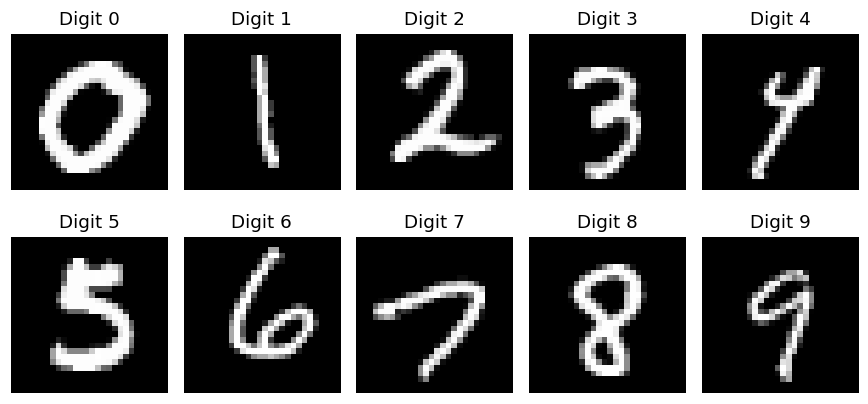

In [3]:
# Show one example image for each digit class.

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for digit, ax in enumerate(axes.ravel()):
    # Pick the first row whose label matches the current digit.
    sample = mnist_df[mnist_df["label"] == digit].iloc[0]

    # Remove the label column and reshape 784 pixel values into a 28 x 28 image.
    image = sample.drop("label").to_numpy(dtype=np.float32).reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
plt.tight_layout()
plt.show()  # Display one example of each digit.


### 6.2 Compare a Fully Connected NN and a CNN

A CNN is a type of neural network. Here, **NN** means a fully connected multilayer perceptron (MLP). We compare the two small architectures from the reference example on the same MNIST data, training both from scratch.

| Feature | Fully connected NN (MLP) | CNN |
|---|---|---|
| Input | 784 flattened pixel values | One 28 × 28 greyscale channel |
| Feature learning | Dense connections across pixel positions | Shared local filters followed by pooling |
| Architecture | 784 → 64 → 10 | Two convolution blocks → 64-unit classifier → 10 |
| Spatial structure | No explicit local neighbourhood structure | Preserves spatial layout during feature extraction |
| Trainable parameters | 50,890 | 105,866 |

The CNN's convolutional layers share weights, but this **whole CNN has more parameters** than this small MLP because its flattened feature maps feed a large dense layer. Fewer convolutional parameters do not guarantee fewer total model parameters.

For a controlled classroom comparison, use one stratified 80/20 split, pixels scaled to [0, 1], batch size 64, Adam with learning rate 0.001 and five epochs for both models. Both return raw logits for cross-entropy loss. Test images never contribute to gradient updates. The architectures have different capacities, so the results describe these two models rather than isolating convolution as the only cause of any accuracy difference.

In [4]:
import torch
from torch import nn

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)  # Reproduce initial weights on the same environment.
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
IMAGE_SIDE = 28
NUM_CLASSES = 10
HIDDEN_UNITS = 64


class SimpleNN(nn.Module):
    """Classify an image using fully connected layers."""

    def __init__(self):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Flatten(),  # Convert each image to a vector of 784 pixels.
            nn.Linear(IMAGE_SIDE * IMAGE_SIDE, HIDDEN_UNITS),
            nn.ReLU(),  # Add a non-linear transformation between dense layers.
            nn.Linear(HIDDEN_UNITS, NUM_CLASSES),  # Return one logit per digit.
        )

    def forward(self, images):
        return self.classifier(images)


class SimpleCNN(nn.Module):
    """Extract local image features before fully connected classification."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),  # Keep 28 × 28 spatial size.
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # Reduce 28 × 28 to 14 × 14.
            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # Learn 32 feature maps.
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # Reduce 14 × 14 to 7 × 7.
        )
        pooled_side = IMAGE_SIDE // 4
        self.classifier = nn.Sequential(
            nn.Flatten(),  # Join all 32 feature maps into one vector per image.
            nn.Linear(32 * pooled_side * pooled_side, HIDDEN_UNITS),
            nn.ReLU(),
            nn.Linear(HIDDEN_UNITS, NUM_CLASSES),  # Cross-entropy accepts logits.
        )

    def forward(self, images):
        return self.classifier(self.features(images))


print(f"Training device: {DEVICE}")

Training device: cpu


#### Prepare one shared training and test split

Keep the image shape `(batch, 1, 28, 28)` for both models. The NN flattens images inside its first layer; the CNN processes their spatial layout. Reusing one split keeps the comparison on the same examples.

In [5]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

TEST_FRACTION = 0.2
BATCH_SIZE = 64

# Scale pixel intensities and split rows before creating image tensors.
digit_pixels = mnist_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
digit_labels = mnist_df["label"].to_numpy(dtype="int64")
train_pixels, test_pixels, train_labels, test_labels = train_test_split(
    digit_pixels, digit_labels,
    test_size=TEST_FRACTION,
    random_state=RANDOM_STATE,
    stratify=digit_labels,  # Preserve similar digit proportions in each split.
)
train_images = torch.from_numpy(train_pixels).reshape(-1, 1, IMAGE_SIDE, IMAGE_SIDE)
test_images = torch.from_numpy(test_pixels).reshape(-1, 1, IMAGE_SIDE, IMAGE_SIDE)
train_targets = torch.from_numpy(train_labels)
test_targets = torch.from_numpy(test_labels)
train_dataset = TensorDataset(train_images, train_targets)
test_loader = DataLoader(
    TensorDataset(test_images, test_targets), batch_size=BATCH_SIZE,
)  # Evaluate small batches to limit memory use.
print(f"Training images: {len(train_images):,}; test images: {len(test_images):,}")

Training images: 4,800; test images: 1,200


#### Train both models with the same settings

For each model, restart the shuffle generator with the same seed so corresponding epochs see the same batch order. Clear old gradients, calculate cross-entropy, backpropagate and update all model parameters. The printed accuracy describes training data only. Fixed seeds improve repeatability; accelerator results can still vary.

In [6]:
EPOCHS = 5
LEARNING_RATE = 0.001


def train_model(model, model_name):
    """Train a model and record loss and accuracy for each epoch."""
    shuffle_generator = torch.Generator().manual_seed(RANDOM_STATE)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE,
        shuffle=True, generator=shuffle_generator,  # Reuse the same batch ordering.
    )
    loss_function = nn.CrossEntropyLoss()  # Use logits without a separate softmax.
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    for epoch in range(EPOCHS):
        model.train()  # Set the model being trained to training mode.
        total_loss = 0.0
        correct_predictions = 0
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimiser.zero_grad()  # Clear gradients left by the previous batch.
            logits = model(images)
            loss = loss_function(logits, labels)
            loss.backward()  # Calculate gradients for this model's parameters.
            optimiser.step()  # Update the parameters using Adam.
            total_loss += loss.item() * len(labels)
            correct_predictions += (logits.argmax(dim=1) == labels).sum().item()
        mean_loss = total_loss / len(train_dataset)
        train_accuracy = correct_predictions / len(train_dataset)
        history.append({"model": model_name, "epoch": epoch + 1,
                        "train_loss": mean_loss, "train_accuracy": train_accuracy})
        print(f"{model_name}, epoch {epoch + 1}/{EPOCHS}: "
              f"loss={mean_loss:.4f}, train accuracy={train_accuracy:.3f}")
    model.eval()  # Prepare the trained model for inference.
    return history


# Reset the seed before initialising each model for repeatable starting weights.
torch.manual_seed(RANDOM_STATE)
simple_nn = SimpleNN().to(DEVICE)
nn_history = train_model(simple_nn, "NN (MLP)")
torch.manual_seed(RANDOM_STATE)
simple_cnn = SimpleCNN().to(DEVICE)
cnn_history = train_model(simple_cnn, "CNN")
training_history = pd.DataFrame(nn_history + cnn_history)

NN (MLP), epoch 1/5: loss=1.3035, train accuracy=0.684
NN (MLP), epoch 2/5: loss=0.5070, train accuracy=0.876
NN (MLP), epoch 3/5: loss=0.3826, train accuracy=0.901
NN (MLP), epoch 4/5: loss=0.3295, train accuracy=0.915
NN (MLP), epoch 5/5: loss=0.2936, train accuracy=0.924
CNN, epoch 1/5: loss=1.2329, train accuracy=0.641
CNN, epoch 2/5: loss=0.3998, train accuracy=0.879
CNN, epoch 3/5: loss=0.2813, train accuracy=0.916
CNN, epoch 4/5: loss=0.2167, train accuracy=0.936
CNN, epoch 5/5: loss=0.1797, train accuracy=0.947


#### Evaluate and compare held-out predictions

Evaluate each trained model on the same test images. Compare test accuracy with parameter counts and training curves. A CNN often benefits from image structure, but these results depend on the dataset, architecture and training budget. Do not assume an accuracy advantage before running the experiment. For further tuning, create a validation split from the training data and keep the test set for final evaluation.

In [7]:
from sklearn.metrics import accuracy_score


def predict_digits(model):
    """Predict test digits in batches without updating model weights."""
    model.eval()  # Evaluate the correct model, including the CNN.
    prediction_batches = []
    with torch.no_grad():  # Disable gradient tracking during evaluation.
        for images, _ in test_loader:
            logits = model(images.to(DEVICE))
            prediction_batches.append(logits.argmax(dim=1).cpu())
    return torch.cat(prediction_batches).numpy()


comparison_rows = []
test_predictions_by_model = {}
for model_name, model in [("NN (MLP)", simple_nn), ("CNN", simple_cnn)]:
    predictions = predict_digits(model)
    test_predictions_by_model[model_name] = predictions
    comparison_rows.append({
        "model": model_name,
        "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "test_accuracy": accuracy_score(test_labels, predictions),
    })
comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,model,trainable_parameters,test_accuracy
0,NN (MLP),50890,0.912500
1,CNN,105866,0.934167


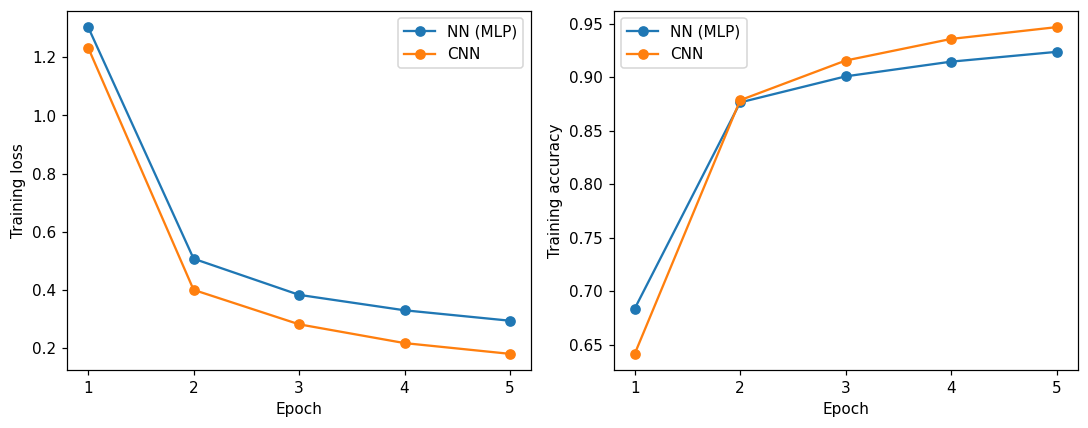

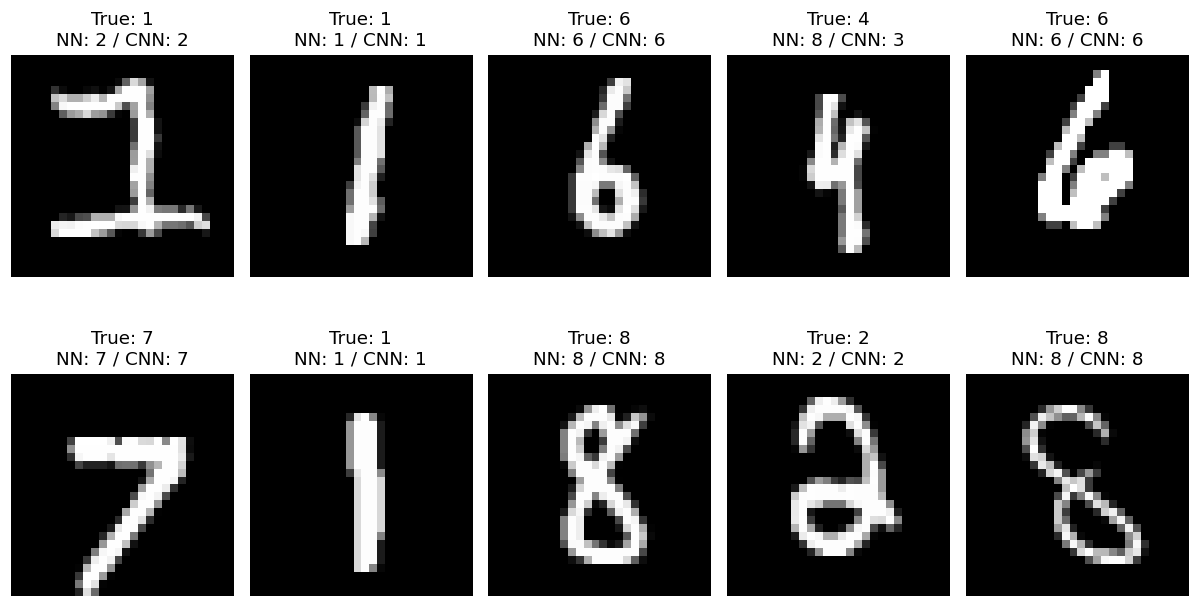

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for model_name, history in training_history.groupby("model", sort=False):
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label=model_name)
    axes[1].plot(history["epoch"], history["train_accuracy"], marker="o", label=model_name)
axes[0].set_ylabel("Training loss")
axes[1].set_ylabel("Training accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks(range(1, EPOCHS + 1))
    ax.legend()
plt.tight_layout()
plt.show()  # Compare learning curves under the same training budget.

PREDICTION_COUNT = 10
PREDICTION_COLUMNS = 5
# Leave room between rows for true labels and both model predictions.
fig, axes = plt.subplots(
    PREDICTION_COUNT // PREDICTION_COLUMNS, PREDICTION_COLUMNS, figsize=(11, 6),
)
for index, ax in enumerate(axes.ravel()):
    ax.imshow(test_images[index].squeeze().numpy(), cmap="gray")
    ax.set_title(
        f"True: {test_labels[index]}\n"
        f"NN: {test_predictions_by_model['NN (MLP)'][index]} / "
        f"CNN: {test_predictions_by_model['CNN'][index]}"
    )
    ax.axis("off")
plt.tight_layout(h_pad=3.0)  # Separate the two rows of prediction labels.
plt.show()  # Inspect both predictions for the same held-out images.

### 6.3 CPU and GPU Inference Comparison

CNN inference contains many parallel convolution operations. A GPU can be faster than a CPU when the model and batch size are large enough. If no GPU is available, the code reports CPU only.

Use the trained `simple_cnn` and a fixed batch of held-out MNIST images shaped `(batch_size, 1, 28, 28)`. The timer measures forward passes after moving the model and batch to the device; it excludes data transfer and training time.


In [9]:
# Import timing utilities only for the CPU/GPU inference comparison.
import time


def synchronise(device: str) -> None:
    """Wait for asynchronous GPU work before reading the timer."""
    # GPU operations can run asynchronously. Synchronising makes the timing fairer.
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps" and hasattr(torch, "mps"):
        torch.mps.synchronize()


def time_inference(model: nn.Module, batch: torch.Tensor, device: str, repeats: int = 5) -> float:
    """Measure average inference time for a model and input batch."""
    model = model.to(device)
    batch = batch.to(device)
    model.eval()

    with torch.no_grad():
        # Warm-up runs reduce one-off setup effects in the timing result.
        for _ in range(3):
            _ = model(batch)
        synchronise(device)

        start = time.perf_counter()
        for _ in range(repeats):
            _ = model(batch)
        synchronise(device)
        end = time.perf_counter()

    return (end - start) / repeats


# Use real greyscale test images with the CNN's expected 28 × 28 shape.
TIMING_BATCH_SIZE = 16
TIMING_REPEATS = 5  # Average several timed forward passes.
sample_batch = test_images[:TIMING_BATCH_SIZE]

# Always test CPU. Add GPU only if PyTorch can see one.
devices = ["cpu"]
if torch.cuda.is_available():
    devices.append("cuda")
elif torch.backends.mps.is_available():
    devices.append("mps")

# Time inference on each available device and collect results in a DataFrame.
timing_rows = []
for device in devices:
    seconds = time_inference(simple_cnn, sample_batch, device, repeats=TIMING_REPEATS)
    timing_rows.append({"device": device, "average_inference_seconds": seconds})

# Move the model back to the default device for later cells.
simple_cnn = simple_cnn.to(DEVICE)
timing_df = pd.DataFrame(timing_rows)
timing_df


,device,average_inference_seconds
0,cpu,0.001344
